In [ ]:
pip install plotly nbformat

   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.7 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.7 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.7 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.7 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.7 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.7 MB 296.6 kB/s eta 0:00:31
   -- ------------------------------------- 0.5/9.7 MB 296.6 kB/s eta 0:00:31
   -- ------------------------------------- 0.5/9.7 MB 296.6 kB/s eta 0:00:31
   -- ------------------------------------- 0.5/9.7 MB 296.6 kB/s eta 0:00:31
   --- ------------------------------------ 0.8/9.7 MB 293.6 kB/s e

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
# Load the cleaned data
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px

df = pd.read_csv("telco_cleaned.csv")
df.head()

,customerid,gender,seniorcitizen,partner,dependents,tenure,phoneservice,multiplelines,internetservice,onlinesecurity,...,deviceprotection,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges,churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Donut chart (customer distribution by tenure)

In [ ]:
# Grouping customers by tenure into 3 categories
bins = [-1, 12, 36, 72]
labels = ["0-12 months", "13-36 months", "37+ months"]
df["tenure_group"] = pd.cut(df["tenure"], bins=bins, labels=labels)

df["tenure_group"].value_counts().sort_index()

tenure_group
0-12 months     2186
13-36 months    1856
37+ months      3001
Name: count, dtype: int64

### Findings: Tenure Groups

Customers were divided into 3 tenure groups:
- **0-12 months:** 2,186 customers (new customers)
- **13-36 months:** 1,856 customers (mid-term customers)
- **37+ months:** 3,001 customers (long-term customers)

Customers with tenure 0 were included in the 0-12 group.

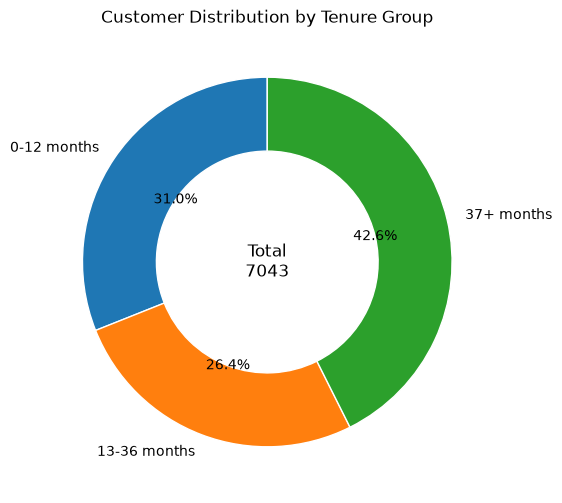

In [ ]:
# Donut chart - customer distribution by tenure group
counts = df["tenure_group"].value_counts().sort_index()

plt.figure(figsize=(6, 6))
plt.pie(counts, labels=counts.index, autopct="%1.1f%%", startangle=90,
        wedgeprops={"width": 0.4, "edgecolor": "white"})
plt.title("Customer Distribution by Tenure Group")
plt.text(0, 0, f"Total\n{counts.sum()}", ha="center", va="center", fontsize=12)
plt.show()

### Findings: Customer Distribution by Tenure (Donut Chart)

- **37+ months is the largest group (42.6%).** Many customers stay long-term with the company.
- **0-12 months makes up 31.0%.** Nearly 1 in 3 customers is in their first year.
- **13-36 months is the smallest group (26.4%).** Fewer customers fall in the middle stage, which suggests many leave before they reach this stage.
- Total customers: **7,043**.

In [5]:
# Interactive donut with Plotly

fig = px.pie(df, names="tenure_group", hole=0.4,
             title="Customer Distribution by Tenure Group (Interactive)",
             category_orders={"tenure_group": labels})
fig.update_traces(textinfo="percent+label")
fig.show()

### Findings: Interactive Donut Chart

- The interactive chart shows the same distribution: 42.6% long-term, 31% new, and 26.4% mid-term customers.
- Hovering over each slice shows the exact customer count, which makes the chart easier to explore.

### Clustered bar chart (average monthly charges)

In [6]:
# Calculate average monthly charges

avg_charges = df.groupby(["tenure_group", "churn"], observed=True)["monthlycharges"].mean().unstack()
avg_charges.round(2)

churn,No,Yes
tenure_group,,
0-12 months,46.71,66.49
13-36 months,57.26,80.70
37+ months,69.68,89.18


### Findings: Average Monthly Charges by Tenure Group and Churn

| Tenure Group | Stayed (No) | Churned (Yes) | Difference |
|---|---|---|---|
| 0-12 months | 46.71 | 66.49 | +19.78 |
| 13-36 months | 57.26 | 80.70 | +23.44 |
| 37+ months | 69.68 | 89.18 | +19.50 |

- In **every tenure group**, customers who churned paid **about 20–23 more per month** than customers who stayed.
- The biggest gap is in the **13-36 months** group (+23.44).

## Clustered bar chart with annotations (Matplotlib)

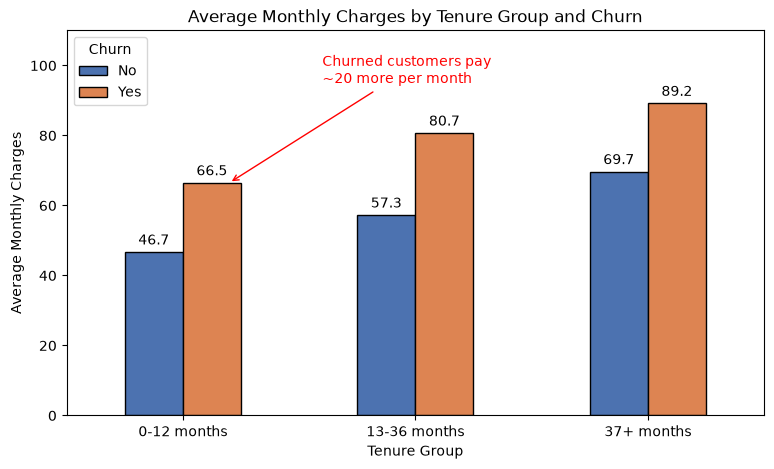

In [7]:
ax = avg_charges.plot(kind="bar", figsize=(9, 5), color=["#4C72B0", "#DD8452"], edgecolor="black")

# Annotations: value on top of each bar
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", padding=3)

# Annotation highlighting a key trend
ax.annotate("Churned customers pay\n~20 more per month",
            xy=(0.2, 66.5), xytext=(0.6, 95),
            arrowprops=dict(arrowstyle="->", color="red"), color="red", fontsize=10)

plt.title("Average Monthly Charges by Tenure Group and Churn")
plt.xlabel("Tenure Group")
plt.ylabel("Average Monthly Charges")
plt.xticks(rotation=0)
plt.ylim(0, 110)
plt.legend(title="Churn")
plt.show()

### Findings: Clustered Bar Chart (with Annotations)

- **Average monthly charges increase with tenure.** Long-term customers tend to use more services (for example fiber internet and streaming), so they pay more.
- **Churned customers (orange bars) always pay more** than retained customers (blue bars) in the same tenure group.
- The red annotation highlights the key trend: churned customers pay **about 20 more per month**.
- **High monthly charges are a strong warning sign of churn**, regardless of how long the customer has been with the company.

## Interactive clustered bar (Plotly)

In [8]:
avg_long = avg_charges.reset_index().melt(id_vars="tenure_group", var_name="churn", value_name="avg_monthly_charges")

fig = px.bar(avg_long, x="tenure_group", y="avg_monthly_charges", color="churn",
             barmode="group", text_auto=".1f",
             title="Average Monthly Charges by Tenure Group and Churn (Interactive)")
fig.add_annotation(x="37+ months", y=89.18, text="Highest: 89.18", showarrow=True, arrowhead=2, yshift=10)
fig.show()

### Findings: Interactive Clustered Bar Chart

- The highest average monthly charge is **89.18**, for **long-term customers (37+ months) who churned**. Even loyal customers leave when bills are high.
- The lowest is **46.71**, for **new customers (0-12 months) who stayed**. Customers on cheaper plans are more likely to stay.
- The interactive chart lets you hover over bars to compare exact values.

## Task 4 Summary

- 42.6% of customers are long-term (37+ months), 31% are new (0-12 months), and 26.4% are mid-term (13-36 months).
- Average monthly charges rise as tenure increases (56.10 → 63.25 → 72.01).
- In all tenure groups, churned customers paid about 20 more per month than customers who stayed.
- **Recommendation:** Offer discounts or better-value plans to high-paying customers, especially in their first year, to reduce churn.